In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
df = pd.read_csv("smartcart_customers.csv")

In [82]:
df.shape

(2240, 22)

In [83]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [84]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Pre-Processing

## Handling Missing Values

In [85]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [86]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

## Feature Engineering

In [87]:
# age

df["Age"] = 2026-df["Year_Birth"]

In [88]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [89]:
# Customer Joining Date

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)

refernce = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (refernce - df["Dt_Customer"]).dt.days

In [90]:
# Total Spending

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [91]:
# Total Children

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [92]:
# Education

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
        "Basic" : "Undergraduate", "2n Cycle" : "Undergraduate",
        "Graduation" : "Graduate",
        "Master" : "Postgraduate", "PhD" : "Postgraduate",
    }
)

In [93]:
# Marital Status

df["Living_With"] = df["Marital_Status"].replace(
    {
        "Married" : "Partner", "Together" :"Partner",
        "Single" : "Alone", "Divorced" : "Alone", "Divorced" : "Alone", 
        "Widow" : "Alone", "Alone" : "Alone", "Absurd" : "Alone", "YOLO" : "Alone",
    }
)

In [94]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

## Drop Columns

In [95]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='object')

In [96]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer" ]

spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns = cols_to_drop)

In [97]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [ ]:
df.shape

# outliers

cols = ["Income", "Recency", "Response", "Age", "Customer_Tenure_Days", "Total_Spending"]

sns.pairplot(df_cleaned[cols])

In [100]:
# Remove Outliers

print("data size with outliers : ", len(df_cleaned))

df_cleaned = df_cleaned[df_cleaned["Age"] < 90]
df_cleaned = df_cleaned[df_cleaned["Income"] < 600000]

print("data size with without outliers : ", len(df_cleaned))


data size with outliers :  2240
data size with without outliers :  2236


In [102]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [105]:
# Heatmap

corr = df_cleaned.corr(numeric_only = True)

<Axes: >

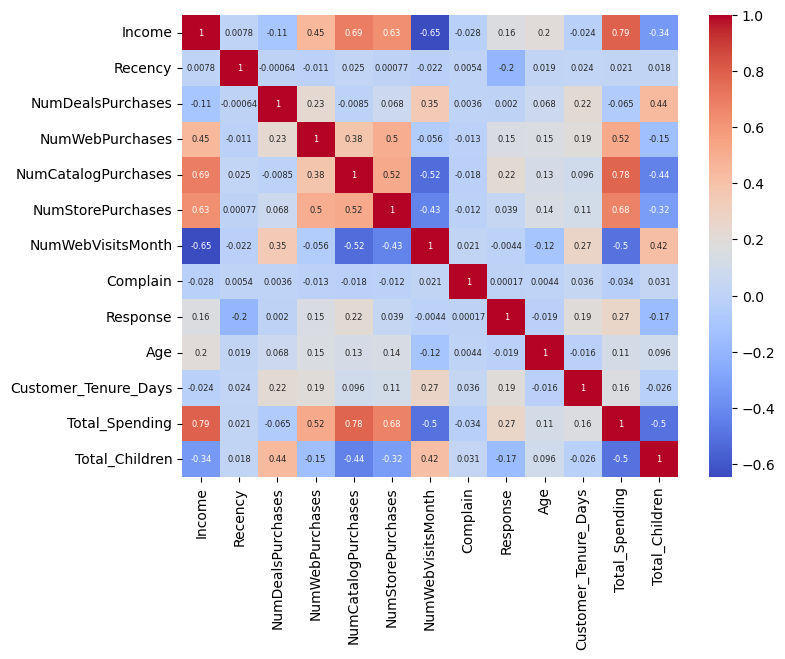

In [121]:
plt.figure(figsize = (8,6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws ={"size" : 6},
    cmap = "coolwarm"
)

## Encoding

In [122]:
from sklearn.preprocessing import OneHotEncoder

In [128]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

encoded_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [130]:
encoded_df = pd.DataFrame(encoded_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [139]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols), encoded_df], axis = 1)

In [140]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


## Scaling

In [141]:
from sklearn.preprocessing import StandardScaler

In [145]:
X = df_encoded

In [146]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## Visualize

In [148]:
X_scaled.shape

(2236, 18)

In [150]:
from sklearn.decomposition import PCA

# 2D

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)

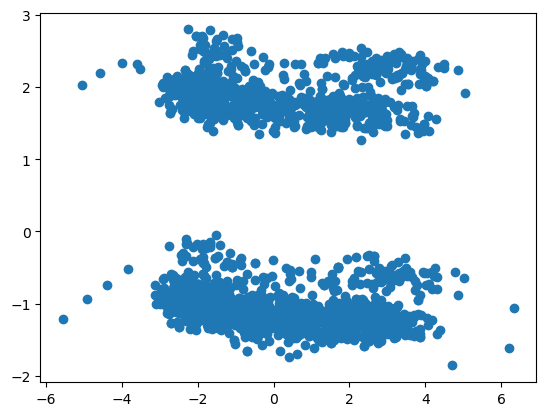

In [153]:
plt.scatter(X_pca[:,0], X_pca[:,1])

In [157]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

In [160]:
# 3D

pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

In [161]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3D Projection')

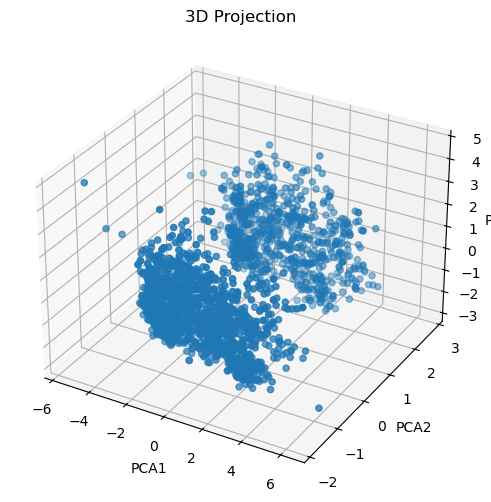

In [173]:
# plot

fig = plt.figure(figsize= (8,6) )

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection")

# Analyze K value

## Elbow Method

In [215]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [216]:
k1 = KneeLocator(range(1,11), wcss, curve = "convex", direction = "decreasing")

In [217]:
print("Optimal K = ", k1.elbow)

Optimal K =  4


Text(0.5, 1.0, 'Elbow Method')

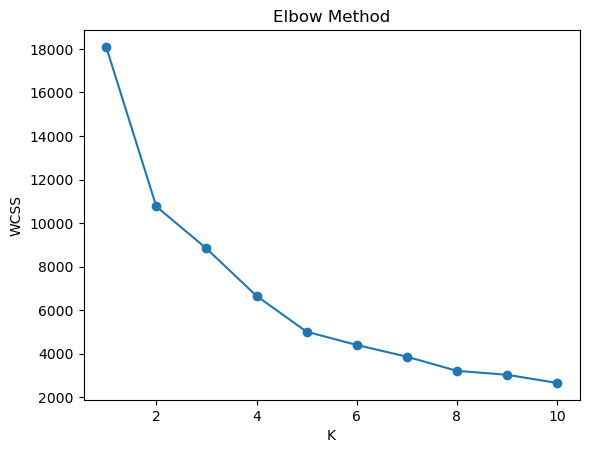

In [221]:
# visualize

plt.plot(range(1,11), wcss, marker = "o")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method")

## Silhouette Score

In [214]:
from sklearn.metrics import silhouette_score

In [227]:
ss = []

for k in range(2,11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    ss.append(silhouette_score(X_pca, labels))

Text(0.5, 1.0, 'Silhouette Score Plot')

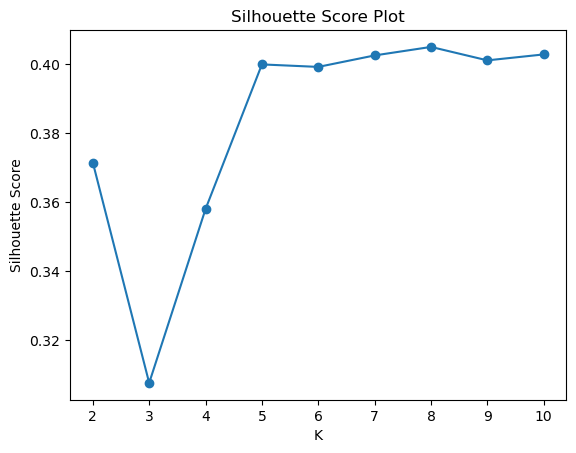

In [230]:
# plot
plt.plot(range(2,11), ss, marker = "o")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Plot")

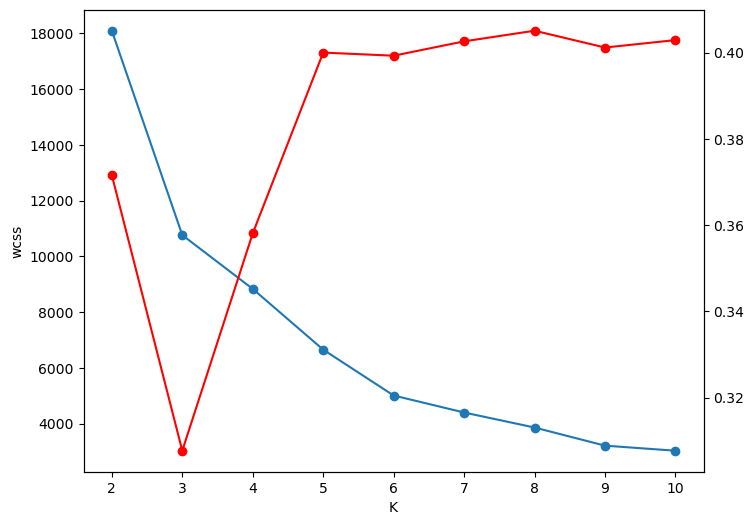

In [245]:
# combined plot

k_range = range(2,11)

fig, ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k_range, wcss[:len(k_range)], marker = "o")
ax1.set_xlabel("K")
ax1.set_ylabel("wcss")

ax2 = ax1.twinx()
ax2.plot(k_range, ss[:len(k_range)], marker = "o", color = "red")

# Clustering

In [249]:
# K-Means

kmeans = KMeans(n_clusters = 4, random_state = 42)

labels_kmeans = kmeans.fit_predict(X_pca)

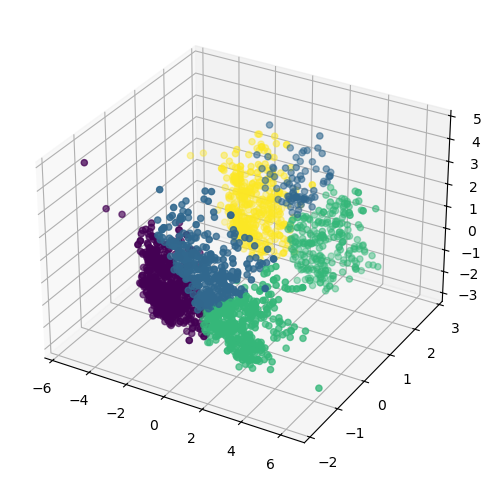

In [250]:
# visualize

fig = plt.figure(figsize= (8,6) )

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c = labels_kmeans )

In [257]:
# Agglomerative

from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters = 4, linkage='ward')

labels_agg = agg.fit_predict(X_pca)

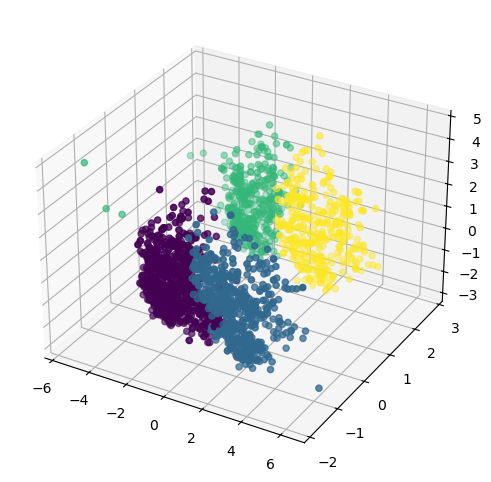

In [258]:
# visualize

fig = plt.figure(figsize= (8,6) )

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c = labels_agg )

# Characterization

In [310]:
X["Cluster"] = labels_agg

In [311]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,Cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='Cluster', ylabel='count'>

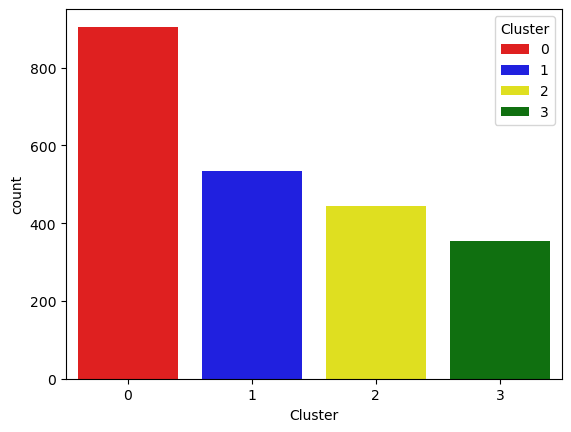

In [312]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x = X["Cluster"], palette = pal, hue = X["Cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

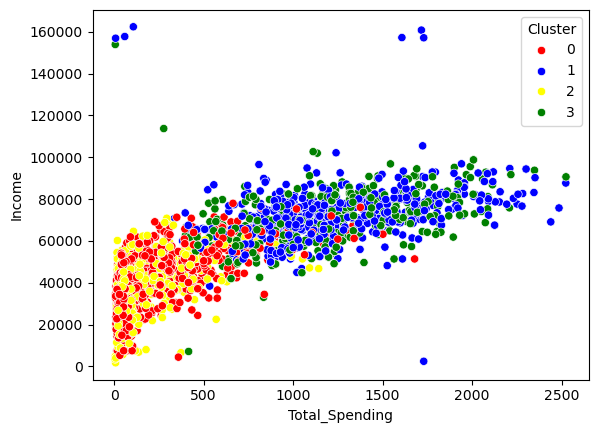

In [313]:
sns.scatterplot(x = X["Total_Spending"], y = X["Income"], hue = X["Cluster"], palette = pal)

In [317]:
# cluster summary

cluster_summary = X.groupby("Cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
Cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
Cluster         